# DTLD Dataset Presentation

This notebook gives a presentation-style overview of the **DTLD** dataset:

- what each scene contains,
- which modalities and annotation files are available (core + optional),
- how frames/objects/visibility are distributed,
- and how RGB, depth, masks, liquid labels, and predictions can be visualized together.

The goal is to understand all available capabilities before training or evaluation.

In [13]:
from __future__ import annotations

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path('..') / 'data' / 'DTLD_dataset'
assert ROOT.exists(), f'Dataset root not found: {ROOT}'

scene_dirs = sorted([p for p in ROOT.iterdir() if p.is_dir()])
scene_ids = [p.name for p in scene_dirs]

print(f'Dataset root: {ROOT}')
print(f'Total scenes: {len(scene_dirs)}')
print('Scene IDs:', ', '.join(scene_ids))

Dataset root: ../data/DTLD_dataset
Total scenes: 14
Scene IDs: 000000, 000001, 000002, 000003, 000004, 000005, 000006, 000007, 000008, 000009, 000010, 000011, 000012, 000013


## Capability audit across scenes

DTLD has a mix of:

- **Core modalities** (present in all scenes): RGB, depth, mask, mask_visib, camera + object annotations.
- **Liquid-specific labels** (present in a subset): `scene_gt_liquid`, `liquid_label`, `scene_gtori`.
- **Prediction artifacts** (in some scene folders): converted curves and scalar liquid-height predictions.

File/modality availability across scenes:
- depth                14/14 scenes
- liquid_label         10/14 scenes
- mask                 14/14 scenes
- mask_visib           14/14 scenes
- mask_visib_liquid     1/14 scenes
- pred_liquid_h.json    1/14 scenes
- preds_converted.json  1/14 scenes
- rgb                  14/14 scenes
- scene_camera.json    14/14 scenes
- scene_gt.json        14/14 scenes
- scene_gt_info.json   14/14 scenes
- scene_gt_liquid.json 11/14 scenes
- scene_gtori.json     11/14 scenes


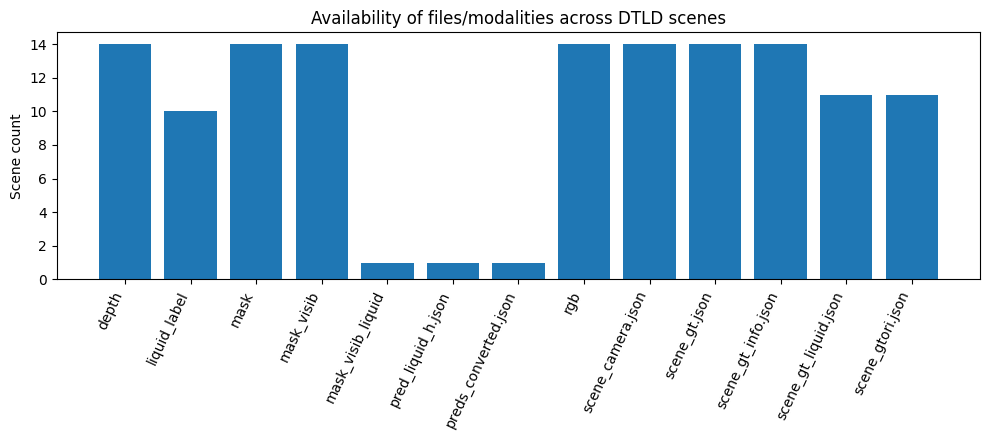

In [14]:
file_presence = Counter()
scene_file_sets = {}

for scene in scene_dirs:
    names = {p.name for p in scene.iterdir()}
    scene_file_sets[scene.name] = names
    for n in names:
        file_presence[n] += 1

print('File/modality availability across scenes:')
for name, count in sorted(file_presence.items()):
    print(f'- {name:<20} {count:>2}/{len(scene_dirs)} scenes')

labels = sorted(file_presence.keys())
counts = [file_presence[k] for k in labels]

plt.figure(figsize=(10, 4.5))
plt.bar(labels, counts)
plt.xticks(rotation=65, ha='right')
plt.ylabel('Scene count')
plt.title('Availability of files/modalities across DTLD scenes')
plt.tight_layout()
plt.show()

## Annotation schema and dataset statistics

From dataset inspection:

- `scene_camera.json` stores camera intrinsics/extrinsics per frame (`cam_K`, `cam_R_w2c`, `cam_t_w2c`, `depth_scale`).
- `scene_gt.json` stores per-object pose with keys like `obj_id`, `cam_R_m2c`, `cam_t_m2c`.
- `scene_gt_info.json` provides object visibility and boxes (`bbox_obj`, `bbox_visib`, `visib_fract`, pixel counts).
- `scene_gt_liquid.json` extends object entries with `liquid_h` and point labels (`liquid_label`).

Total frames across scenes: 27,482
Total object annotations (scene_gt): 109,866
Unique object IDs: 4

Top object IDs by frequency:
- obj_id=17: 27,482
- obj_id=16: 27,482
- obj_id=19: 27,482
- obj_id=15: 27,420

Visibility fraction summary:
- min: 0.000
- median: 1.000
- max: 1.000

Liquid height summary (from scene_gt_liquid):
- min: 14.70
- median: 45.10
- max: 96.00


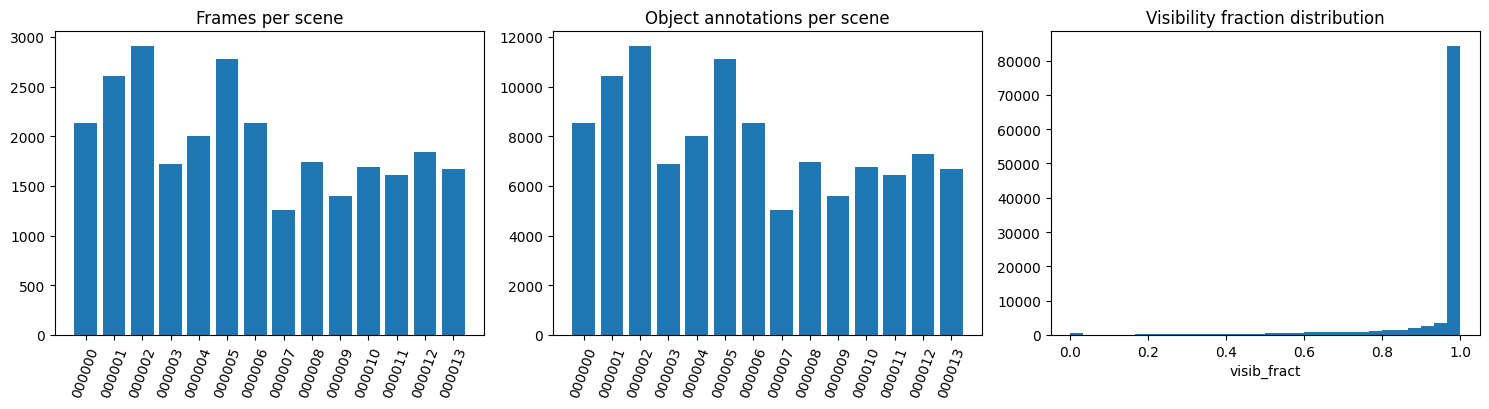

In [15]:
import re

def load_json(path: Path):
    if not path.exists():
        return None

    raw = path.read_bytes()
    decoded_variants = []
    for encoding in ('utf-8', 'latin-1'):
        try:
            txt = raw.decode(encoding, errors='replace')
            decoded_variants.append(txt)
        except Exception:
            pass

    for txt in decoded_variants:
        candidates = [
            txt,
            txt.replace('\x00', ''),
            re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f]', '', txt),
        ]
        for cand in candidates:
            try:
                return json.loads(cand)
            except json.JSONDecodeError:
                continue

    if path.name == 'scene_gt_info.json' and decoded_variants:
        txt = decoded_variants[0]
        vals = [float(v) for v in re.findall(r'"visib_fract"\s*:\s*([0-9]*\.?[0-9]+)', txt)]
        if vals:
            return {'__visib_fract_only__': vals}

    return None

scene_frame_counts = {}
scene_obj_counts = {}
obj_id_counter = Counter()
visib_fracts = []
liquid_h_values = []

for scene in scene_dirs:
    scene_id = scene.name
    cam = load_json(scene / 'scene_camera.json')
    gt = load_json(scene / 'scene_gt.json')
    gt_info = load_json(scene / 'scene_gt_info.json')
    gt_liquid = load_json(scene / 'scene_gt_liquid.json')

    n_frames = len(cam) if isinstance(cam, dict) else 0
    scene_frame_counts[scene_id] = n_frames

    total_objects = 0
    if isinstance(gt, dict):
        for frame_objs in gt.values():
            total_objects += len(frame_objs)
            for obj in frame_objs:
                obj_id = obj.get('obj_id')
                if obj_id is not None:
                    obj_id_counter[obj_id] += 1
    scene_obj_counts[scene_id] = total_objects

    if isinstance(gt_info, dict):
        if '__visib_fract_only__' in gt_info:
            visib_fracts.extend(gt_info['__visib_fract_only__'])
        else:
            for frame_infos in gt_info.values():
                for info in frame_infos:
                    vf = info.get('visib_fract')
                    if vf is not None:
                        visib_fracts.append(float(vf))

    if isinstance(gt_liquid, dict):
        for frame_objs in gt_liquid.values():
            for obj in frame_objs:
                lh = obj.get('liquid_h')
                if lh is not None:
                    liquid_h_values.append(float(lh))

total_frames = sum(scene_frame_counts.values())
total_objects = sum(scene_obj_counts.values())

print(f'Total frames across scenes: {total_frames:,}')
print(f'Total object annotations (scene_gt): {total_objects:,}')
print(f'Unique object IDs: {len(obj_id_counter)}')

print('\nTop object IDs by frequency:')
for obj_id, cnt in obj_id_counter.most_common(10):
    print(f'- obj_id={obj_id}: {cnt:,}')

if visib_fracts:
    arr = np.array(visib_fracts)
    print('\nVisibility fraction summary:')
    print(f'- min: {arr.min():.3f}')
    print(f'- median: {np.median(arr):.3f}')
    print(f'- max: {arr.max():.3f}')

if liquid_h_values:
    arr_h = np.array(liquid_h_values)
    print('\nLiquid height summary (from scene_gt_liquid):')
    print(f'- min: {arr_h.min():.2f}')
    print(f'- median: {np.median(arr_h):.2f}')
    print(f'- max: {arr_h.max():.2f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].bar(list(scene_frame_counts.keys()), list(scene_frame_counts.values()))
axes[0].set_title('Frames per scene')
axes[0].tick_params(axis='x', rotation=70)

axes[1].bar(list(scene_obj_counts.keys()), list(scene_obj_counts.values()))
axes[1].set_title('Object annotations per scene')
axes[1].tick_params(axis='x', rotation=70)

axes[2].hist(visib_fracts, bins=30)
axes[2].set_title('Visibility fraction distribution')
axes[2].set_xlabel('visib_fract')

plt.tight_layout()
plt.show()

## Multi-modal frame panel

The next cell shows all available visual modalities for a selected frame:

- RGB
- depth
- mask
- visible mask
- liquid-specific masks when present (`liquid_label`, `mask_visib_liquid`)

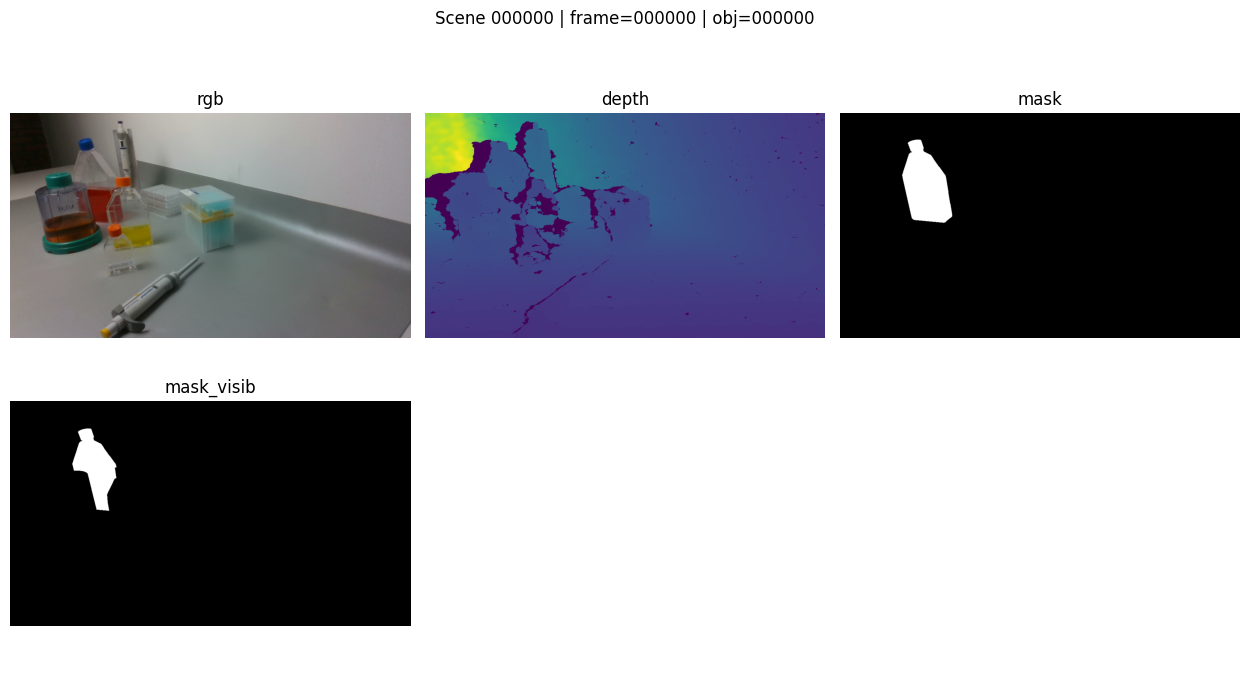

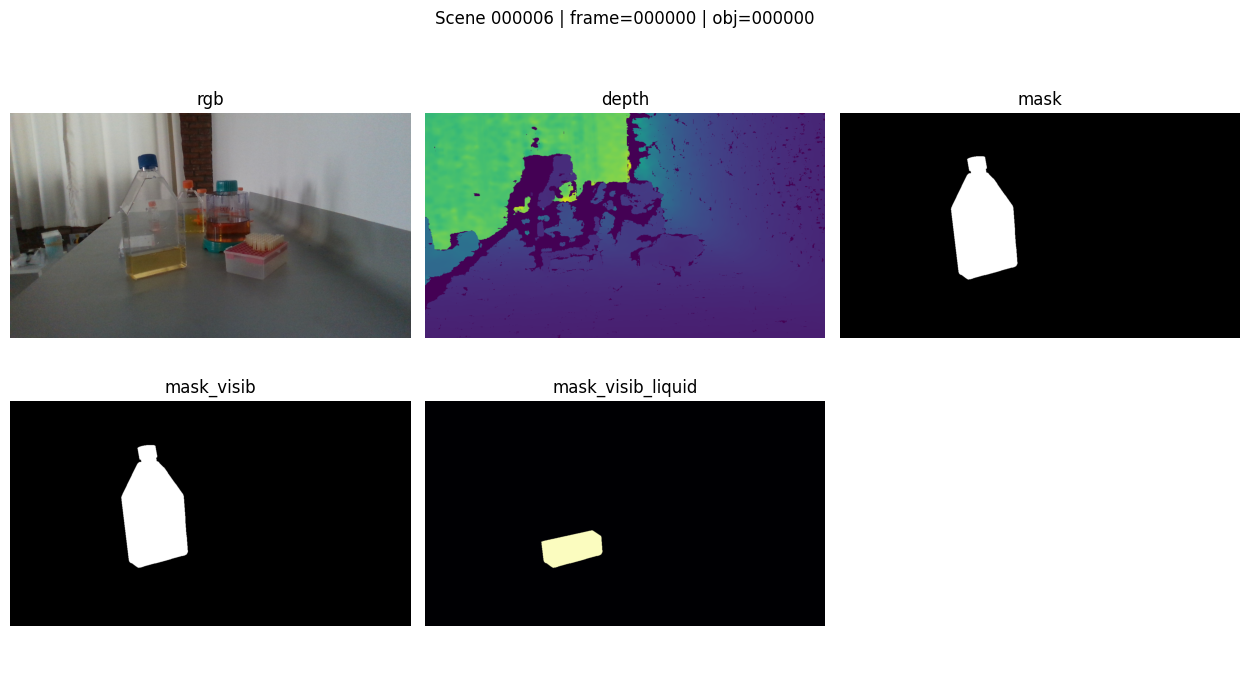

In [16]:
def read_img(path: Path):
    if not path.exists():
        return None
    return plt.imread(path)


def show_modalities(scene_id: str, frame_idx: int = 0, obj_idx: int = 0):
    scene_path = ROOT / scene_id
    frame_name = f'{frame_idx:06d}.png'
    mask_name = f'{frame_idx:06d}_{obj_idx:06d}.png'

    items = [
        ('rgb', scene_path / 'rgb' / frame_name, None),
        ('depth', scene_path / 'depth' / frame_name, 'viridis'),
        ('mask', scene_path / 'mask' / mask_name, 'gray'),
        ('mask_visib', scene_path / 'mask_visib' / mask_name, 'gray'),
        ('liquid_label', scene_path / 'liquid_label' / mask_name, 'magma'),
        ('mask_visib_liquid', scene_path / 'mask_visib_liquid' / mask_name, 'magma'),
    ]

    valid_items = []
    for label, path, cmap in items:
        img = read_img(path)
        if img is not None:
            valid_items.append((label, img, cmap, path))

    if not valid_items:
        print(f'No images found for scene={scene_id}, frame={frame_idx}, obj={obj_idx}')
        return

    cols = 3
    rows = int(np.ceil(len(valid_items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.3 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (label, img, cmap, path) in zip(axes, valid_items):
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap)
        else:
            ax.imshow(img)
        ax.set_title(label)
        ax.axis('off')

    for ax in axes[len(valid_items):]:
        ax.axis('off')

    fig.suptitle(f'Scene {scene_id} | frame={frame_idx:06d} | obj={obj_idx:06d}', y=1.02)
    plt.tight_layout()
    plt.show()


# Representative scenes: one core-only scene + one with richer liquid/prediction artifacts
show_modalities('000000', frame_idx=0, obj_idx=0)
show_modalities('000006', frame_idx=0, obj_idx=0)

## Overlaying annotations on RGB

This view overlays:

- `bbox_obj` and `bbox_visib` from `scene_gt_info.json`,
- and liquid keypoints (`A, B, C, D`) from `scene_gt_liquid.json` when available.

Using scene=000000, frame=0


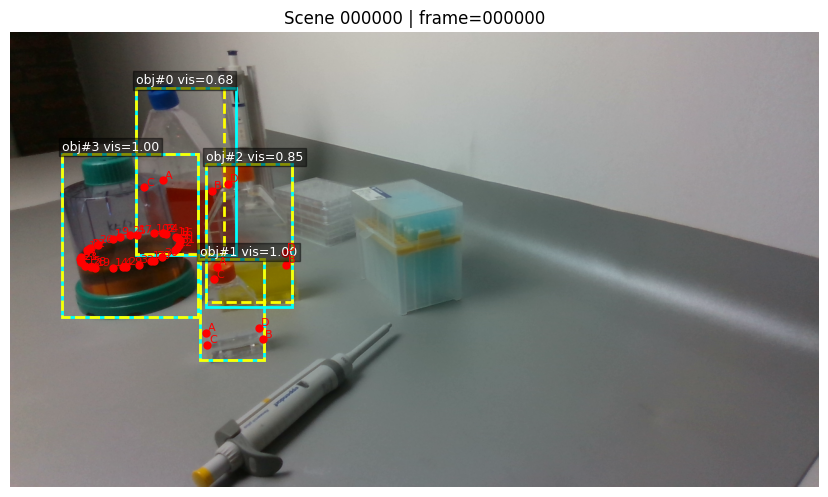

In [17]:
def overlay_annotations(scene_id: str, frame_idx: int = 0, obj_limit: int = 4):
    scene_path = ROOT / scene_id
    frame_key = str(frame_idx)

    rgb_path = scene_path / 'rgb' / f'{frame_idx:06d}.png'
    rgb = read_img(rgb_path)
    if rgb is None:
        print(f'RGB image missing: {rgb_path}')
        return

    gt_info = load_json(scene_path / 'scene_gt_info.json') or {}
    gt_liquid = load_json(scene_path / 'scene_gt_liquid.json') or {}

    infos = gt_info.get(frame_key, [])
    liquids = gt_liquid.get(frame_key, [])

    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.imshow(rgb)
    ax.set_title(f'Scene {scene_id} | frame={frame_idx:06d}')

    for idx, info in enumerate(infos[:obj_limit]):
        bbox_obj = info.get('bbox_obj', [])
        bbox_vis = info.get('bbox_visib', [])

        if len(bbox_obj) == 4:
            x, y, w, h = bbox_obj
            rect = plt.Rectangle((x, y), w, h, fill=False, linewidth=2, color='cyan')
            ax.add_patch(rect)

        if len(bbox_vis) == 4:
            x, y, w, h = bbox_vis
            rect = plt.Rectangle((x, y), w, h, fill=False, linewidth=2, linestyle='--', color='yellow')
            ax.add_patch(rect)

        ax.text(
            bbox_obj[0] if len(bbox_obj) == 4 else 5,
            (bbox_obj[1] - 6) if len(bbox_obj) == 4 else (20 + idx * 18),
            f'obj#{idx} vis={info.get("visib_fract", np.nan):.2f}',
            color='white',
            fontsize=9,
            bbox=dict(facecolor='black', alpha=0.45, pad=2),
        )

    for obj in liquids[:obj_limit]:
        lbl = obj.get('liquid_label', {})
        for k, pt in lbl.items():
            if isinstance(pt, list) and len(pt) == 2:
                ax.scatter(pt[0], pt[1], s=25, color='red')
                ax.text(pt[0] + 3, pt[1] - 3, f'{k}', color='red', fontsize=8)

    ax.axis('off')
    plt.tight_layout()
    plt.show()


# Find a scene/frame with liquid labels, fallback to a default
chosen_scene, chosen_frame = None, None
for scene in scene_dirs:
    gt_liq = load_json(scene / 'scene_gt_liquid.json')
    if isinstance(gt_liq, dict) and len(gt_liq) > 0:
        for k, v in gt_liq.items():
            if v and isinstance(v[0], dict) and 'liquid_label' in v[0]:
                chosen_scene = scene.name
                chosen_frame = int(k)
                break
    if chosen_scene is not None:
        break

if chosen_scene is None:
    chosen_scene, chosen_frame = '000000', 0

print(f'Using scene={chosen_scene}, frame={chosen_frame}')
overlay_annotations(chosen_scene, chosen_frame, obj_limit=4)

## Optional prediction artifacts

Some scene folders include model outputs such as:

- `pred_liquid_h.json`: scalar height predictions per mask path,
- `preds_converted.json`: polyline/curve predictions.

The cell below summarizes and visualizes these when available.

Prediction scene: 000006
- pred_liquid_h entries: 46
- preds_converted entries: 8,370


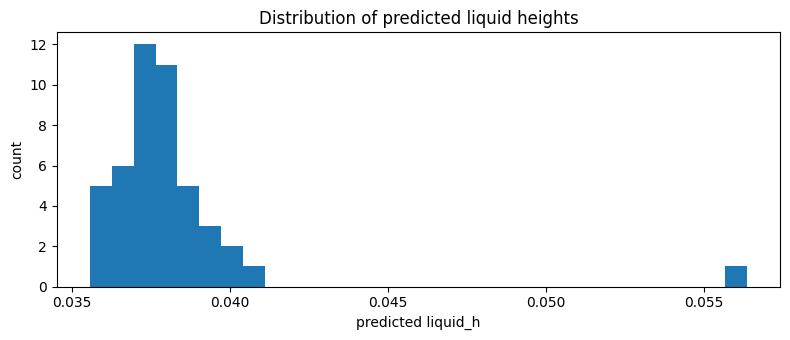

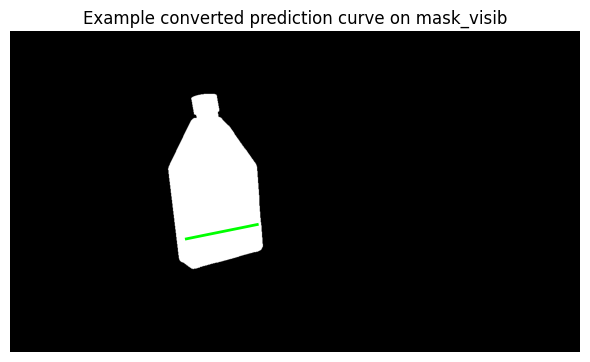

In [18]:
pred_scene = None
for s in scene_dirs:
    if (s / 'pred_liquid_h.json').exists() and (s / 'preds_converted.json').exists():
        pred_scene = s
        break

if pred_scene is None:
    print('No scene with both prediction files found.')
else:
    print(f'Prediction scene: {pred_scene.name}')

    pred_h = load_json(pred_scene / 'pred_liquid_h.json') or {}
    pred_curve = load_json(pred_scene / 'preds_converted.json') or {}

    print(f'- pred_liquid_h entries: {len(pred_h):,}')
    print(f'- preds_converted entries: {len(pred_curve):,}')

    if pred_h:
        vals = np.array(list(pred_h.values()), dtype=float)
        plt.figure(figsize=(8, 3.5))
        plt.hist(vals, bins=30)
        plt.title('Distribution of predicted liquid heights')
        plt.xlabel('predicted liquid_h')
        plt.ylabel('count')
        plt.tight_layout()
        plt.show()

    example_key = None
    for k, pts in pred_curve.items():
        if isinstance(pts, list) and len(pts) > 0:
            example_key = k
            break

    if example_key is not None:
        rel_idx = example_key.split('/mask_visib/')[-1]
        local_mask = pred_scene / 'mask_visib' / rel_idx
        pts = np.array(pred_curve[example_key], dtype=float)

        if local_mask.exists():
            img = read_img(local_mask)
            plt.figure(figsize=(6, 4.5))
            if img.ndim == 2:
                plt.imshow(img, cmap='gray')
            else:
                plt.imshow(img)
            plt.plot(pts[:, 0], pts[:, 1], color='lime', linewidth=2)
            plt.title('Example converted prediction curve on mask_visib')
            plt.axis('off')
            plt.tight_layout()
            plt.show()
        else:
            plt.figure(figsize=(6, 3.5))
            plt.plot(pts[:, 0], pts[:, 1], color='lime', linewidth=2)
            plt.title('Example converted prediction curve (no local mask match)')
            plt.gca().invert_yaxis()
            plt.tight_layout()
            plt.show()

## Takeaways

- DTLD is a **multi-scene, multi-frame, multi-modal** dataset with strong core coverage (RGB/depth/masks/poses).
- It includes **instance-level visibility and geometry metadata** suitable for perception/pose tasks.
- A subset of scenes adds **liquid-specific supervision** (`liquid_h`, labeled liquid points, liquid masks).
- Some scenes also store **prediction artifacts**, enabling error analysis and qualitative benchmarking.

This notebook can serve as a reusable dataset presentation before model development.